# Decision Tree

This notebook trains and evaluates a baseline Decision Tree, then tunes the
tree using cross-validation on the training data only. The goal is to compare
baseline and tuned performance and check whether tuning reduces overfitting.

In [1]:
from pathlib import Path
import sys

ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "data/processed/hotel_booking_features.csv").is_file()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

from scripts.model_evaluation_utils import (
    RANDOM_STATE,
    OUTPUT_DIR,
    load_feature_dataset,
    split_feature_dataset,
    class_distribution,
    build_pipeline,
    get_cv,
    cross_validation_summary,
    fit_and_evaluate,
    confusion_matrix_frame,
    save_results,
)

FIGURE_DIR = OUTPUT_DIR / "Figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load Shared Data Split

In [2]:
data = load_feature_dataset()
prepared = split_feature_dataset(data)

print(f"Training rows: {len(prepared.X_train):,}")
print(f"Test rows: {len(prepared.X_test):,}")

print("\nTraining class distribution")
display(class_distribution(prepared.y_train))

print("\nTest class distribution")
display(class_distribution(prepared.y_test))

Training rows: 95,364
Test rows: 23,841

Training class distribution


,class,count,percent
0,0,60008,62.9252
1,1,35356,37.0748



Test class distribution


,class,count,percent
0,0,15002,62.9252
1,1,8839,37.0748


## 2. Baseline Decision Tree

In [3]:
tree_model = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_pipeline = build_pipeline(tree_model, prepared.X_train)
tree_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",1.0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be exclude

## 3. Baseline Cross-Validation

In [4]:
tree_cv = cross_validation_summary(
    "Decision Tree",
    "Baseline",
    tree_pipeline,
    prepared.X_train,
    prepared.y_train,
)
display(tree_cv.round(4))

,model,version,metric,train_mean,train_std,cv_mean,cv_std
0,Decision Tree,Baseline,accuracy,0.9957,0.0002,0.8541,0.0026
1,Decision Tree,Baseline,precision,0.9965,0.0006,0.8020,0.0044
2,Decision Tree,Baseline,recall,0.9919,0.0004,0.8052,0.0058
3,Decision Tree,Baseline,f1,0.9942,0.0002,0.8036,0.0036
4,Decision Tree,Baseline,roc_auc,0.9999,0.0000,0.8463,0.0027
5,Decision Tree,Baseline,pr_auc,0.9999,0.0000,0.7224,0.0044


In [5]:
baseline_gap = tree_cv.assign(
    train_cv_gap=tree_cv["train_mean"] - tree_cv["cv_mean"]
)
display(baseline_gap[["metric", "train_mean", "cv_mean", "train_cv_gap"]].round(4))

,metric,train_mean,cv_mean,train_cv_gap
0,accuracy,0.9957,0.8541,0.1416
1,precision,0.9965,0.8020,0.1945
2,recall,0.9919,0.8052,0.1867
3,f1,0.9942,0.8036,0.1906
4,roc_auc,0.9999,0.8463,0.1537
5,pr_auc,0.9999,0.7224,0.2775


**Baseline interpretation:** A Decision Tree can capture non-linear patterns
and feature interactions, but an unrestricted tree can memorize the training
data. The train-vs-CV gap table is used to check overfitting. A large gap,
especially for F1, suggests that the baseline tree is too complex.

## 4. Baseline Final Test Evaluation

In [6]:
tree_pipeline, tree_test = fit_and_evaluate(
    "Decision Tree",
    "Baseline",
    tree_pipeline,
    prepared,
)

tree_test_results = pd.DataFrame([tree_test])
display(tree_test_results.round(4))

,model,version,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
0,Decision Tree,Baseline,0.8595,0.8075,0.8154,0.8114,0.8528,0.7316,7.8892


## 5. Baseline Confusion Matrix

In [7]:
tree_predictions = tree_pipeline.predict(prepared.X_test)
tree_confusion = confusion_matrix_frame(prepared.y_test, tree_predictions)
display(tree_confusion)

,Predicted 0,Predicted 1
Actual 0,13284,1718
Actual 1,1632,7207


## 6. Decision Tree Tuning

The grid search uses F1-score because cancellation prediction should balance
precision and recall. Tuning is performed with training data and
cross-validation only.

In [8]:
tuned_tree_base = build_pipeline(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    prepared.X_train,
)

tree_param_grid = {
    "model__max_depth": [6, 10],
    "model__min_samples_split": [20, 100],
    "model__min_samples_leaf": [10, 25],
    "model__criterion": ["gini", "entropy"],
}

tree_search = GridSearchCV(
    estimator=tuned_tree_base,
    param_grid=tree_param_grid,
    scoring="f1",
    cv=get_cv(),
    n_jobs=-1,
    return_train_score=True,
)
tree_search.fit(prepared.X_train, prepared.y_train)

print("Best Decision Tree parameters:")
print(tree_search.best_params_)
print(f"Best CV F1: {tree_search.best_score_:.4f}")

Best Decision Tree parameters:
{'model__criterion': 'gini', 'model__max_depth': 10, 'model__min_samples_leaf': 10, 'model__min_samples_split': 20}
Best CV F1: 0.7827


**Tuning choice:** F1-score is used for tuning because cancellation
prediction needs a balance between precision and recall. False positives may
cause unnecessary follow-up actions, while false negatives mean the hotel may
miss bookings that are likely to cancel. ROC-AUC and PR-AUC are still
reported to understand ranking and probability discrimination beyond one
fixed threshold.

## 7. Tuned Cross-Validation

In [9]:
tuned_tree_pipeline = tree_search.best_estimator_

tuned_tree_cv = cross_validation_summary(
    "Decision Tree",
    "Tuned",
    tuned_tree_pipeline,
    prepared.X_train,
    prepared.y_train,
)
display(tuned_tree_cv.round(4))

,model,version,metric,train_mean,train_std,cv_mean,cv_std
0,Decision Tree,Tuned,accuracy,0.8477,0.0009,0.8452,0.0025
1,Decision Tree,Tuned,precision,0.8202,0.0044,0.8163,0.0062
2,Decision Tree,Tuned,recall,0.7548,0.0048,0.7518,0.0073
3,Decision Tree,Tuned,f1,0.7861,0.0013,0.7827,0.0037
4,Decision Tree,Tuned,roc_auc,0.9259,0.0005,0.9223,0.0019
5,Decision Tree,Tuned,pr_auc,0.8755,0.0005,0.8715,0.0030


In [10]:
tuned_gap = tuned_tree_cv.assign(
    train_cv_gap=tuned_tree_cv["train_mean"] - tuned_tree_cv["cv_mean"]
)
display(tuned_gap[["metric", "train_mean", "cv_mean", "train_cv_gap"]].round(4))

,metric,train_mean,cv_mean,train_cv_gap
0,accuracy,0.8477,0.8452,0.0025
1,precision,0.8202,0.8163,0.0039
2,recall,0.7548,0.7518,0.0029
3,f1,0.7861,0.7827,0.0034
4,roc_auc,0.9259,0.9223,0.0037
5,pr_auc,0.8755,0.8715,0.0039


**Tuned model interpretation:** The tuned tree should reduce the training
score compared with the unrestricted baseline. That is expected and usually
desirable when the baseline has a large train-vs-CV gap. The important
question is whether validation and test performance become more reliable.

## 8. Tuned Final Test Evaluation

In [11]:
tuned_tree_pipeline, tuned_tree_test = fit_and_evaluate(
    "Decision Tree",
    "Tuned",
    tuned_tree_pipeline,
    prepared,
)

tuned_tree_test_results = pd.DataFrame([tuned_tree_test])
display(tuned_tree_test_results.round(4))

,model,version,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
0,Decision Tree,Tuned,0.8462,0.8189,0.7513,0.7836,0.9226,0.8728,1.2798


## 9. Tuned Confusion Matrix

In [12]:
tuned_tree_predictions = tuned_tree_pipeline.predict(prepared.X_test)
tuned_tree_confusion = confusion_matrix_frame(prepared.y_test, tuned_tree_predictions)
display(tuned_tree_confusion)

,Predicted 0,Predicted 1
Actual 0,13533,1469
Actual 1,2198,6641


## 10. Baseline vs Tuned Comparison

In [13]:
decision_tree_test_results = pd.DataFrame([
    tree_test,
    tuned_tree_test,
])
decision_tree_cv_results = pd.concat([
    tree_cv,
    tuned_tree_cv,
], ignore_index=True)

display(decision_tree_test_results.round(4))
display(decision_tree_cv_results.round(4))

,model,version,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
0,Decision Tree,Baseline,0.8595,0.8075,0.8154,0.8114,0.8528,0.7316,7.8892
1,Decision Tree,Tuned,0.8462,0.8189,0.7513,0.7836,0.9226,0.8728,1.2798


,model,version,metric,train_mean,train_std,cv_mean,cv_std
0,Decision Tree,Baseline,accuracy,0.9957,0.0002,0.8541,0.0026
1,Decision Tree,Baseline,precision,0.9965,0.0006,0.8020,0.0044
2,Decision Tree,Baseline,recall,0.9919,0.0004,0.8052,0.0058
3,Decision Tree,Baseline,f1,0.9942,0.0002,0.8036,0.0036
4,Decision Tree,Baseline,roc_auc,0.9999,0.0000,0.8463,0.0027
5,Decision Tree,Baseline,pr_auc,0.9999,0.0000,0.7224,0.0044
6,Decision Tree,Tuned,accuracy,0.8477,0.0009,0.8452,0.0025
7,Decision Tree,Tuned,precision,0.8202,0.0044,0.8163,0.0062
8,Decision Tree,Tuned,recall,0.7548,0.0048,0.7518,0.0073
9,Decision Tree,Tuned,f1,0.7861,0.0013,0.7827,0.0037


In [14]:
f1_comparison = decision_tree_test_results.loc[
    :, ["version", "precision", "recall", "f1", "roc_auc", "pr_auc"]
]
display(f1_comparison.round(4))

,version,precision,recall,f1,roc_auc,pr_auc
0,Baseline,0.8075,0.8154,0.8114,0.8528,0.7316
1,Tuned,0.8189,0.7513,0.7836,0.9226,0.8728


**Comparison interpretation:** The tuned tree should not be described as
better on every metric unless the table supports that claim. If tuned F1 is
lower but ROC-AUC and PR-AUC are higher, the correct conclusion is that
tuning improved ranking/probability discrimination and reduced overfitting,
while the default-threshold F1 did not improve. This trade-off is important
for the final model comparison.

## 11. ROC and Precision-Recall Curves

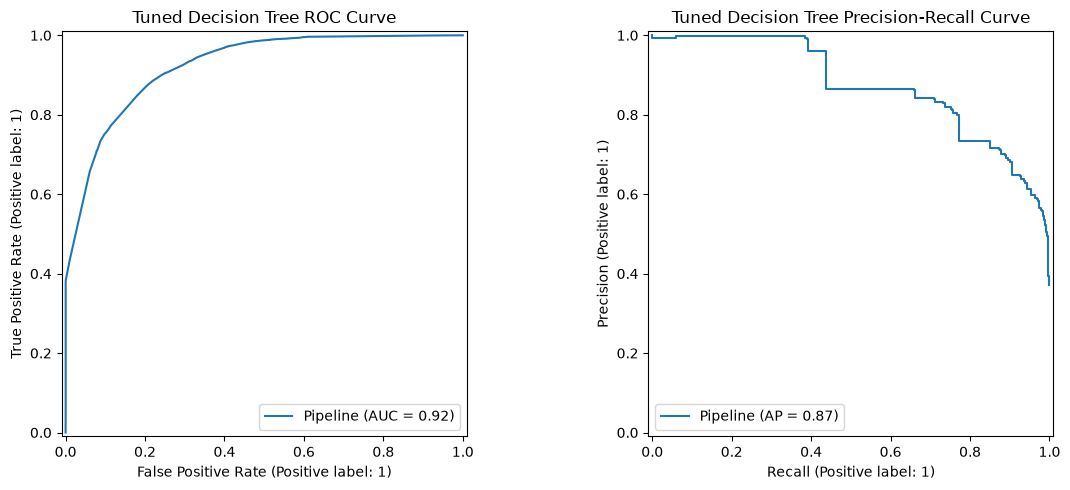

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_estimator(tuned_tree_pipeline, prepared.X_test, prepared.y_test, ax=axes[0])
PrecisionRecallDisplay.from_estimator(tuned_tree_pipeline, prepared.X_test, prepared.y_test, ax=axes[1])
axes[0].set_title("Tuned Decision Tree ROC Curve")
axes[1].set_title("Tuned Decision Tree Precision-Recall Curve")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "decision_tree_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 12. Tree Visualization

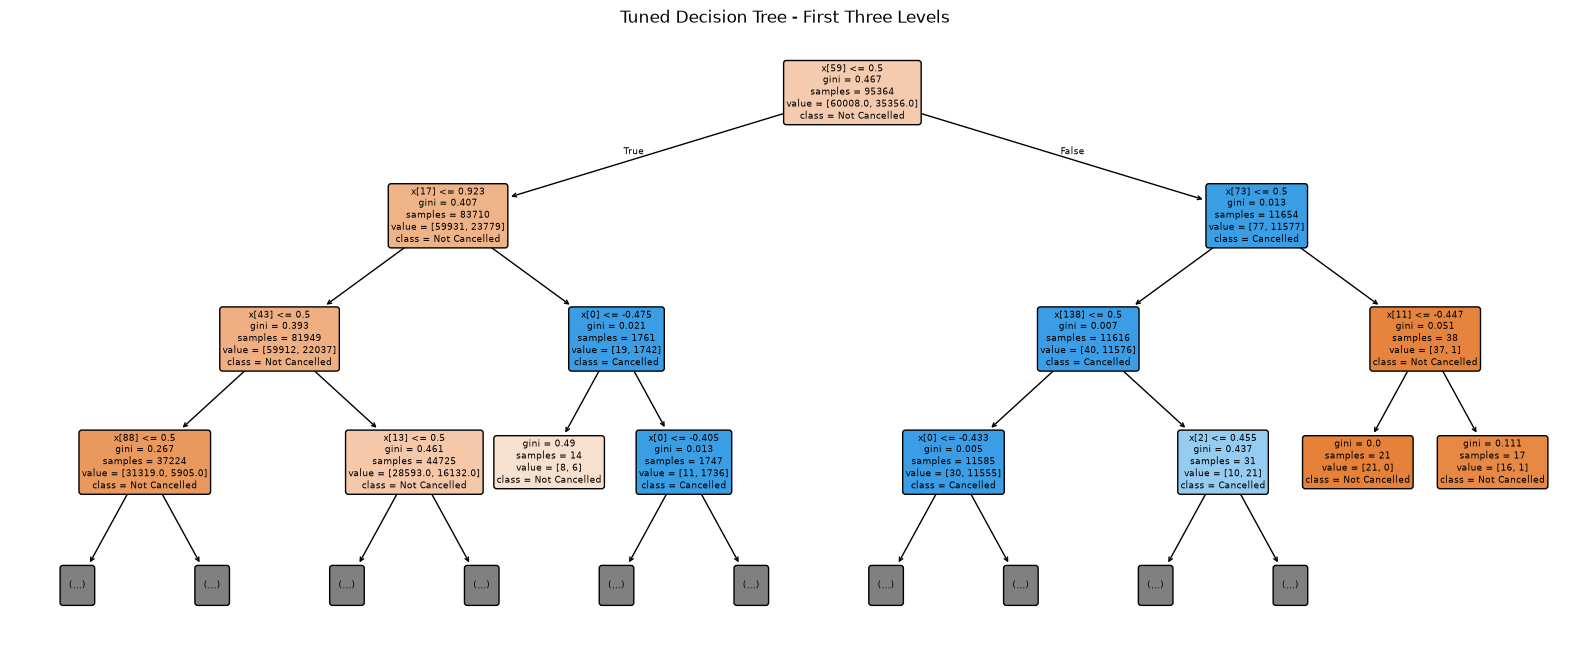

In [16]:
fitted_tree = tuned_tree_pipeline.named_steps["model"]

plt.figure(figsize=(20, 8))
plot_tree(
    fitted_tree,
    max_depth=3,
    filled=True,
    rounded=True,
    class_names=["Not Cancelled", "Cancelled"],
)
plt.title("Tuned Decision Tree - First Three Levels")
plt.savefig(FIGURE_DIR / "decision_tree_visualization.png", dpi=300, bbox_inches="tight")
plt.show()

## 13. Save Results

In [17]:
test_path = save_results(decision_tree_test_results, "decision_tree_test_results.csv")
cv_path = save_results(decision_tree_cv_results, "decision_tree_cv_results.csv")

print(f"Saved final test results to: {test_path.relative_to(ROOT)}")
print(f"Saved CV results to: {cv_path.relative_to(ROOT)}")

Saved final test results to: 06_Model_Evaluation\decision_tree_test_results.csv
Saved CV results to: 06_Model_Evaluation\decision_tree_cv_results.csv


## 14. Interpretation Notes

The baseline Decision Tree is expected to achieve very high training scores
because it can grow deep and memorize patterns. The tuned tree is more
constrained, so its training score may be lower, but its validation gap and
probability-based metrics can be stronger. Keep both baseline and tuned
results for the final comparison and explain the precision-recall trade-off
clearly.